# Лабораторная 7. Автоэнкодеры

**Задание.** Реализовать автоэнкодеры: а) автоэнкодер с полносвязными слоями;
б) вариационный автоэнкодер.

Для обеих моделей, используя выборки MNIST и FashionMNIST:

1) реализовать различные варианты зашумления и исследовать, как зависит качество
нормализации изображения (очистки от шума): а) от типа зашумления (равномерный
шум, нормальный шум, локальная порча изображений); б) от размерности пространства
скрытых признаков; в) от количества и ширины слоёв кодера и декодера; а также от
гиперпараметров: г) количества эпох; д) коэффициента обучения;

2) оценить качество изображений, восстановленных из чистых и зашумлённых
изображений;

3) оценить возможность генерирования новых изображений из случайных точек в
латентном пространстве (пространстве скрытых признаков).

## 1. Теория

### Данные

MNIST и FashionMNIST: изображения $28 \times 28$ в градациях серого. Из обучающей
части каждой выборки берутся 8000 изображений для обучения и 1000 отложенных для
сравнения гиперпараметров, из тестовой части 1000 изображений для итоговой оценки.
Яркости делятся на 255, изображение разворачивается в вектор длины 784.

### Автоэнкодер

Кодер $f$ и декодер $g$ из полносвязных слоёв обучаются восстанавливать вход:

$$z = f(x), \qquad \hat x = g(z), \qquad L = \lVert x - \hat x\rVert^2 .$$

Размерность кода $z$ (пространства скрытых признаков) меньше 784, поэтому сеть
сжимает изображение до $d$ чисел. В скрытых слоях функция активации
$\mathrm{ReLU}(t) = \max(0, t)$, слой кода линеен. Декодер повторяет слои кодера
в обратном порядке, на его выходе сигмоида $1/(1 + e^{-t})$, чтобы яркости
лежали в $[0, 1]$.

### Очистка от шума

Очистка от шума - это нормализация изображения: зашумлённое изображение
приводится к чистому виду. Сеть обучается на парах "зашумлённое изображение на
входе, чистое на выходе":

$$L = \lVert x - g(f(\tilde x))\rVert^2, \qquad \tilde x = \text{шум}(x).$$

Виды зашумления с уровнем $\ell$:

- равномерный шум: к каждому пикселю добавляется $\mathrm{U}[-\ell, \ell]$;
- нормальный шум: к каждому пикселю добавляется $\mathrm{N}(0, \ell^2)$;
- локальная порча: два квадратных пятна случайного положения со стороной $28\ell$,
  но не меньше 4 пикселей, заполненные случайными значениями.

После добавки шума значения обрезаются до $[0, 1]$.

### Вариационный автоэнкодер

Кодер выдаёт параметры распределения кода $\mu(x)$ и $\log\sigma^2(x)$, код
берётся как $z = \mu + \sigma\varepsilon$, где $\varepsilon \sim \mathcal{N}(0, I)$.
Функция потерь

$$L = \lVert x - \hat x\rVert^2
    - \frac12\sum_{j}\bigl(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\bigr).$$

Второе слагаемое - мера Кульбака-Лейблера между $\mathcal{N}(\mu_j, \sigma_j^2)$ и
$\mathcal{N}(0, 1)$, сложенная по координатам кода. Она стягивает распределение
кодов к $\mathcal{N}(0, I)$, поэтому для генерации код берётся из
$\mathcal{N}(0, I)$. При восстановлении изображения берётся $z = \mu$.

### Меры качества

Средняя квадратичная ошибка по пикселям

$$\mathrm{MSE} = \frac{1}{n}\sum_k (x_k - \hat x_k)^2 .$$

SSIM (structural similarity) сравнивает изображения $a$ и $b$ по окнам
$7 \times 7$. В каждом окне

$$\mathrm{SSIM} = \frac{(2 m_a m_b + C_1)(2 s_{ab} + C_2)}
{(m_a^2 + m_b^2 + C_1)(s_a^2 + s_b^2 + C_2)},$$

где $m_a$, $m_b$ - средние яркости в окне, $s_a^2$, $s_b^2$ - дисперсии, $s_{ab}$ -
ковариация, $C_1 = 0.01^2$, $C_2 = 0.03^2$. Значения усредняются по окнам. Первый
множитель сравнивает яркость, второй контраст и структуру, значение 1 означает
совпадение. Обе меры считаются между чистым изображением и выходом сети. В таблицах `mse_noisy`, `ssim_noisy` относятся к
восстановлению по зашумлённому изображению, `mse_clean`, `ssim_clean` к
восстановлению по чистому, `mse_input`, `ssim_input` к самому зашумлённому
изображению без обработки.

### Что перебирается

| Параметр | Значения | Базовое значение |
|---|---|---|
| тип шума | равномерный, нормальный, пятна | нормальный |
| уровень шума $\ell$ | $0.2$, $0.4$ | $0.3$ |
| размерность кода $d$ | 2, 4, 8, 16, 32, 64 | 32 |
| скрытые слои кодера | $(128)$, $(256)$, $(512, 256)$, $(512, 256, 128)$ | $(256)$ |
| число эпох | 10, 20, 40 | 20 |
| коэффициент обучения | $3\cdot10^{-4}$, $10^{-3}$, $3\cdot10^{-3}$ | $10^{-3}$ |

Перебор проводится для обеих моделей и обеих выборок. На каждом этапе меняется
один параметр, остальные берутся базовыми. Число эпох и коэффициент обучения
перебираются вместе: модель обучается 40 эпох, качество замеряется после 10, 20 и
40 эпох. Качество сравнивается на отложенных изображениях по MSE восстановления
по зашумлённому. Итоговые модели берут лучшие значения $d$, слоёв, числа эпох и
коэффициента обучения. Оптимизатор Adam: вместо градиента берётся скользящее
среднее градиентов, а шаг по каждому весу делится на корень из скользящего
среднего квадратов его градиентов. Батч 128, градиенты находит torch методом
обратного распространения ошибки.

## 2. Данные и модели шума

In [1]:
import os
import struct
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity

torch.manual_seed(20260905)
plt.rcParams['figure.dpi'] = 110

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__}, устройство: {DEVICE}')

torch 2.11.0+cu128, устройство: cuda


In [2]:
def read_idx(path):
    with open(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        dims = struct.unpack('>' + 'I' * (magic & 0xff), f.read(4 * (magic & 0xff)))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def find_dir(name, env):
    for c in [os.environ.get(env), f'../data/{name}/raw', f'data/{name}/raw',
              '../../bachelor/Perceptron/data_generation/MNIST/raw' if name == 'MNIST' else None]:
        if c and Path(c, 'train-images-idx3-ubyte').exists():
            return Path(c)
    raise FileNotFoundError(name)


def load(name, env, n_train, n_val, n_test, rng):
    """Обучающая и отложенная части из обучающей выборки, тестовая из тестовой."""
    D = find_dir(name, env)
    Xtr = read_idx(D / 'train-images-idx3-ubyte')
    Xte = read_idx(D / 't10k-images-idx3-ubyte')
    perm = rng.permutation(len(Xtr))
    itr, ival = perm[:n_train], perm[n_train:n_train + n_val]  # части не пересекаются
    ite = rng.choice(len(Xte), n_test, replace=False)
    return (Xtr[itr].astype(np.float32) / 255.0, Xtr[ival].astype(np.float32) / 255.0,
            Xte[ite].astype(np.float32) / 255.0)


DATA = {
    'MNIST': load('MNIST', 'MNIST_DIR', 8000, 1000, 1000, np.random.default_rng(20260905)),
    'FashionMNIST': load('FashionMNIST', 'FASHION_DIR', 8000, 1000, 1000,
                         np.random.default_rng(20260905)),
}
for k, (a, b, c) in DATA.items():
    print(f'{k}: обучающая {a.shape}, отложенная {b.shape}, тестовая {c.shape}')

MNIST: обучающая (8000, 28, 28), отложенная (1000, 28, 28), тестовая (1000, 28, 28)
FashionMNIST: обучающая (8000, 28, 28), отложенная (1000, 28, 28), тестовая (1000, 28, 28)


In [3]:
def noise_uniform(X, level, rng):
    """Равномерный шум: добавка U[-level, level] к каждому пикселю."""
    return np.clip(X + rng.uniform(-level, level, X.shape), 0, 1).astype(np.float32)


def noise_normal(X, level, rng):
    """Нормальный шум с sigma = level."""
    return np.clip(X + rng.normal(0, level, X.shape), 0, 1).astype(np.float32)


def noise_blot(X, level, rng):
    """Локальная порча: квадратные пятна случайного положения."""
    X = X.copy()
    size = max(4, int(round(28 * level)))
    n_blots = 2
    for i in range(len(X)):
        for _ in range(n_blots):
            r0 = rng.integers(0, 28 - size + 1)
            c0 = rng.integers(0, 28 - size + 1)
            X[i, r0:r0 + size, c0:c0 + size] = rng.random((size, size))
    return X.astype(np.float32)


NOISES = {'равномерный': noise_uniform, 'нормальный': noise_normal,
          'пятна': noise_blot}

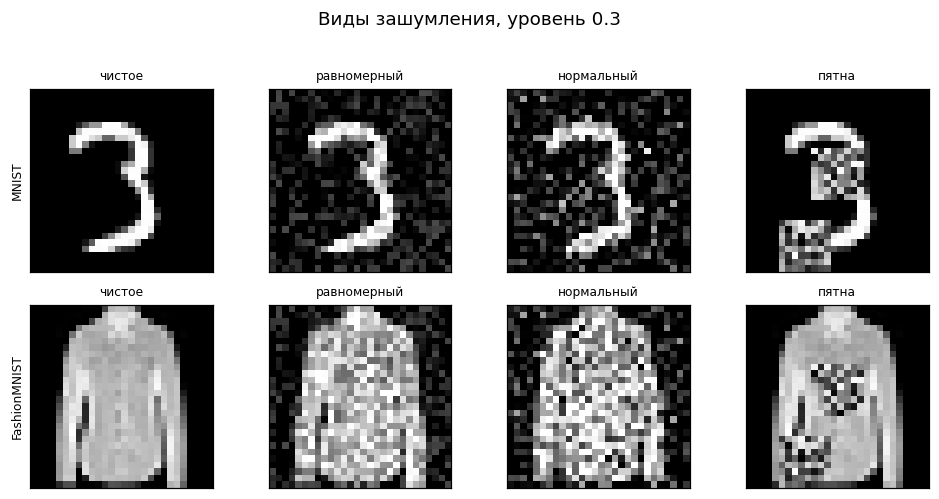

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(9, 4.4))
for row, ds in enumerate(['MNIST', 'FashionMNIST']):
    X = DATA[ds][1]
    axes[row, 0].imshow(X[0], cmap='gray'); axes[row, 0].set_title('чистое', fontsize=8)
    for col, (name, f) in enumerate(NOISES.items(), start=1):
        axes[row, col].imshow(f(X[:1], 0.3, np.random.default_rng(1))[0], cmap='gray')
        axes[row, col].set_title(name, fontsize=8)
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(ds, fontsize=8)
fig.suptitle('Виды зашумления, уровень 0.3', y=1.02)
plt.tight_layout()
plt.show()

## 3. Автоэнкодер и вариационный автоэнкодер

In [5]:
def dense_stack(dims):
    """Полносвязные слои с ReLU между ними по размерам dims."""
    layers = []
    for a, b in zip(dims[:-1], dims[1:]):
        layers += [nn.Linear(a, b), nn.ReLU()]
    return layers


class AE(nn.Module):
    """Автоэнкодер с полносвязными слоями."""

    def __init__(self, latent=16, hidden=(256,)):
        super().__init__()
        self.latent = latent
        hidden = list(hidden)
        # кодер сужает 784 до latent, декодер разворачивает обратно теми же ширинами
        self.encoder = nn.Sequential(*dense_stack([784] + hidden),
                                     nn.Linear(hidden[-1], latent))
        self.decoder = nn.Sequential(*dense_stack([latent] + hidden[::-1]),
                                     nn.Linear(hidden[0], 784), nn.Sigmoid())

    def forward(self, x):
        return self.decoder(self.encoder(x)), None

    def sample(self, n):
        """Декодирование n случайных точек латентного пространства."""
        device = next(self.parameters()).device  # где лежат веса, там и считаем
        return self.decoder(torch.randn(n, self.latent, device=device))


class VAE(nn.Module):
    """Вариационный автоэнкодер."""

    def __init__(self, latent=16, hidden=(256,)):
        super().__init__()
        self.latent = latent
        hidden = list(hidden)
        self.encoder = nn.Sequential(*dense_stack([784] + hidden))
        self.mu = nn.Linear(hidden[-1], latent)          # среднее распределения кодов
        self.logvar = nn.Linear(hidden[-1], latent)      # логарифм дисперсии
        self.decoder = nn.Sequential(*dense_stack([latent] + hidden[::-1]),
                                     nn.Linear(hidden[0], 784), nn.Sigmoid())

    def forward(self, x):
        h = self.encoder(x)
        mu, logvar = self.mu(h), self.logvar(h)
        if not self.training:  # при оценке код берётся равным среднему
            return self.decoder(mu), (mu, logvar)
        # репараметризация: z = mu + sigma * eps, случайность вынесена в eps
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), (mu, logvar)

    def sample(self, n):
        device = next(self.parameters()).device
        return self.decoder(torch.randn(n, self.latent, device=device))

In [6]:
def train_ae(model, Xn, Xc, epochs, lr, batch=128, seed=0, after_epoch=None):
    """Xn это вход (возможно зашумлённый), Xc это цель (чистое изображение).
    after_epoch, если задана, вызывается с номером эпохи после каждой эпохи."""
    torch.manual_seed(seed)
    model.to(DEVICE)  # веса переносятся на видеокарту, если она есть
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    xn = torch.tensor(Xn.reshape(len(Xn), -1)).to(DEVICE)  # каждое изображение в строку
    xc = torch.tensor(Xc.reshape(len(Xc), -1)).to(DEVICE)
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(xn), device=DEVICE)  # новый порядок объектов
        for s in range(0, len(xn), batch):
            b = perm[s:s + batch]
            out, extra = model(xn[b])
            loss = ((out - xc[b]) ** 2).sum(1).mean()  # квадрат нормы x - x_hat, среднее по батчу
            if extra is not None:  # у VAE добавляется KL-слагаемое
                mu, logvar = extra
                kl = -0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(1).mean()
                loss = loss + kl
            opt.zero_grad()  # обнуление градиентов прошлого шага
            loss.backward()  # градиенты функции потерь по весам
            opt.step()  # шаг оптимизатора
        if after_epoch is not None:
            after_epoch(epoch)


def reconstruct(model, X):
    """Прогон изображений через сеть и обратно в форму (N, 28, 28)."""
    model.eval()
    with torch.no_grad():  # при оценке градиенты не нужны
        out, _ = model(torch.tensor(X.reshape(len(X), -1)).to(DEVICE))
    return out.cpu().numpy().reshape(-1, 28, 28)  # .cpu() забирает результат с видеокарты


def quality(ref, rec):
    """MSE по пикселям и средний SSIM по изображениям."""
    mse = float(np.mean((ref - rec) ** 2))
    ssim = float(np.mean([structural_similarity(a, b, data_range=1.0)
                          for a, b in zip(ref, rec)]))
    return mse, ssim

In [7]:
MODELS = {'AE': AE, 'VAE': VAE}
DATASETS = ['MNIST', 'FashionMNIST']
BASE = dict(noise='нормальный', level=0.3, latent=32, hidden=(256,), epochs=20, lr=1e-3)


def experiment(stage, ds, model_name, **changes):
    """Обучение модели с базовыми параметрами, часть которых заменена, и замер на отложенной."""
    cfg = {**BASE, **changes}  # параметры BASE, часть из них заменена
    Xtr, Xval, _ = DATA[ds]
    noise = NOISES[cfg['noise']]
    Xtr_n = noise(Xtr, cfg['level'], np.random.default_rng(20260905))
    Xval_n = noise(Xval, cfg['level'], np.random.default_rng(1))
    torch.manual_seed(20260905)
    model = MODELS[model_name](latent=cfg['latent'], hidden=cfg['hidden'])
    train_ae(model, Xtr_n, Xtr, epochs=cfg['epochs'], lr=cfg['lr'])
    mse_n, ssim_n = quality(Xval, reconstruct(model, Xval_n))
    mse_c, ssim_c = quality(Xval, reconstruct(model, Xval))
    row = dict(stage=stage, dataset=ds, model=model_name, **cfg,
               mse_noisy=mse_n, ssim_noisy=ssim_n, mse_clean=mse_c, ssim_clean=ssim_c,
               params=sum(p.numel() for p in model.parameters()))
    return row, model


def show(df, index, value):
    """Таблица: строки - значения параметра, столбцы - выборка и модель."""
    piv = df.pivot_table(index=index, columns=['dataset', 'model'], values=value)
    piv = piv[[(d, m) for d in DATASETS for m in MODELS]]
    print((piv.astype(int) if value == 'params' else piv.round(4)).to_string())

## 4. Пункт 1а: тип и уровень зашумления

In [8]:
rows, denoisers = [], {}
for ds in DATASETS:
    Xval = DATA[ds][1]
    for model_name in MODELS:
        for nname in NOISES:
            for level in [0.2, 0.4]:
                row, model = experiment('шум', ds, model_name, noise=nname, level=level)
                # качество самого зашумлённого входа, с ним сравнивается выход сети
                Xval_n = NOISES[nname](Xval, level, np.random.default_rng(1))
                row['mse_input'], row['ssim_input'] = quality(Xval, Xval_n)
                rows.append(row)
                if model_name == 'AE' and level == 0.4:
                    denoisers[(ds, nname)] = model
noi = pd.DataFrame(rows)
print(noi[['dataset', 'model', 'noise', 'level', 'mse_input', 'mse_noisy',
           'ssim_input', 'ssim_noisy']].round(4).to_string(index=False))

     dataset model       noise  level  mse_input  mse_noisy  ssim_input  ssim_noisy
       MNIST    AE равномерный    0.2     0.0073     0.0125      0.6761      0.8413
       MNIST    AE равномерный    0.4     0.0284     0.0150      0.5774      0.8120
       MNIST    AE  нормальный    0.2     0.0211     0.0141      0.6095      0.8222
       MNIST    AE  нормальный    0.4     0.0794     0.0195      0.4436      0.7527
       MNIST    AE       пятна    0.2     0.0274     0.0186      0.8094      0.7654
       MNIST    AE       пятна    0.4     0.0824     0.0355      0.5350      0.5807
       MNIST   VAE равномерный    0.2     0.0073     0.0253      0.6761      0.6277
       MNIST   VAE равномерный    0.4     0.0284     0.0271      0.5774      0.6054
       MNIST   VAE  нормальный    0.2     0.0211     0.0267      0.6095      0.6151
       MNIST   VAE  нормальный    0.4     0.0794     0.0316      0.4436      0.5660
       MNIST   VAE       пятна    0.2     0.0274     0.0296      0.8094     

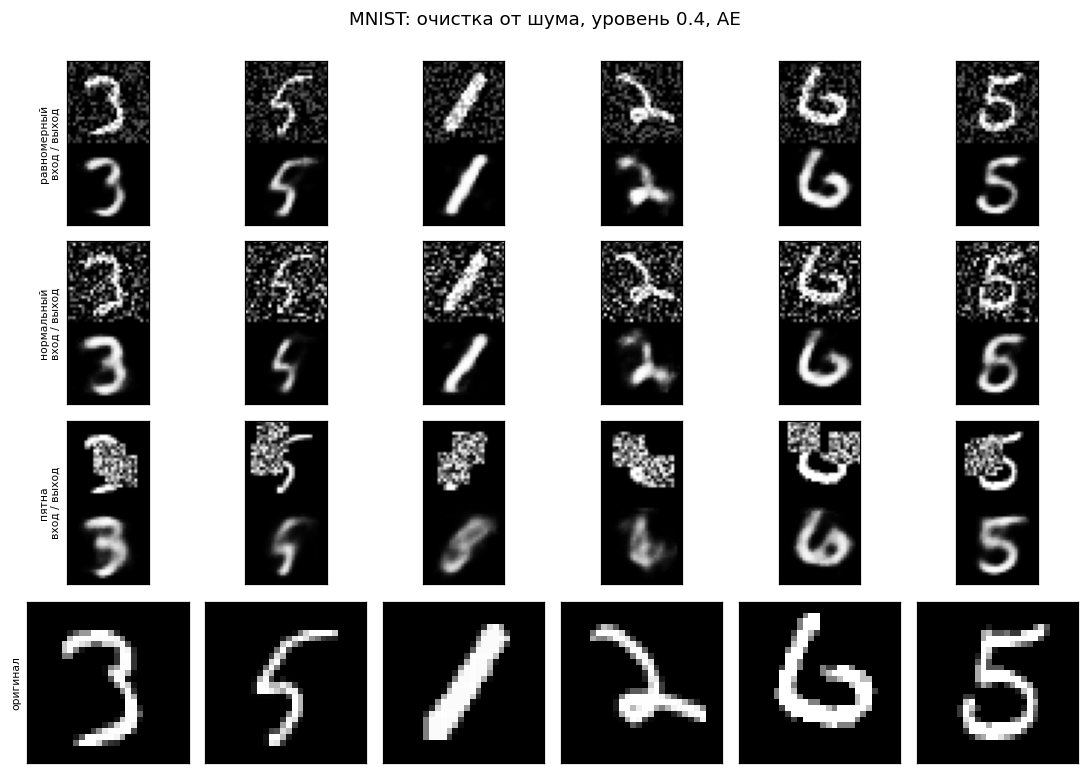

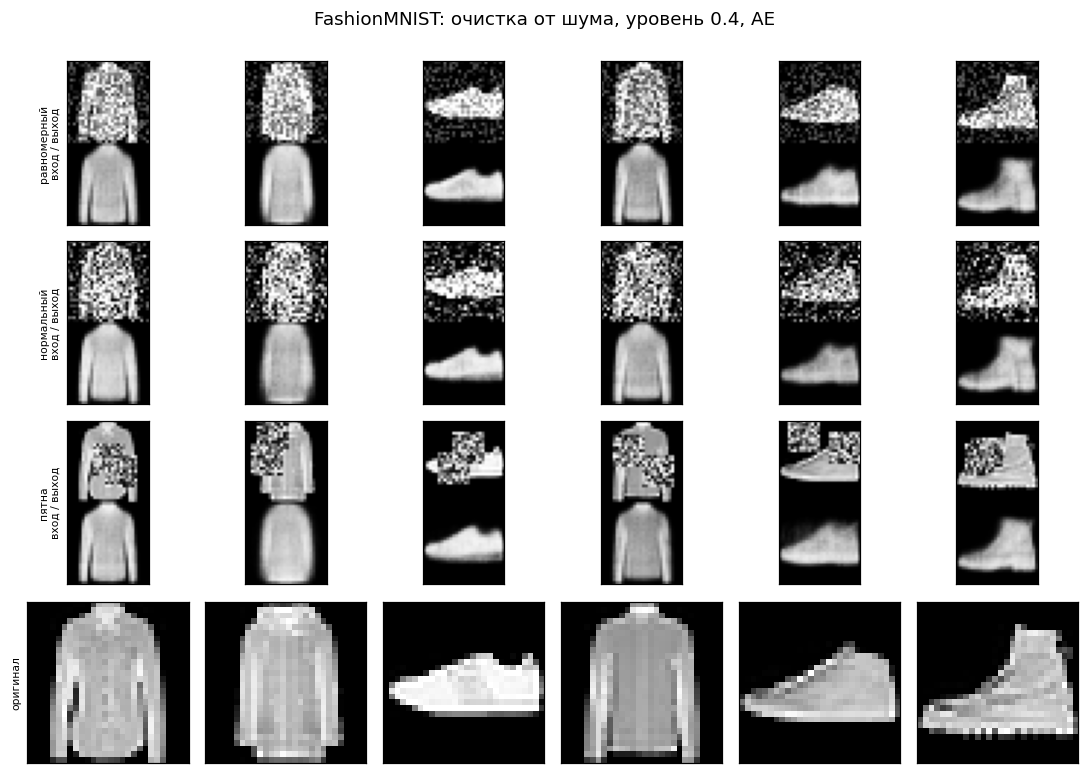

In [9]:
for ds in DATASETS:
    Xval = DATA[ds][1]
    fig, axes = plt.subplots(4, 6, figsize=(10, 7))
    for row, nname in enumerate(NOISES):
        Xval_n = NOISES[nname](Xval, 0.4, np.random.default_rng(1))
        rec = reconstruct(denoisers[(ds, nname)], Xval_n)
        for col in range(6):
            # vstack ставит вход над выходом, получается две строки в одной картинке
            axes[row, col].imshow(np.vstack([Xval_n[col], rec[col]]), cmap='gray')
            axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
        axes[row, 0].set_ylabel(f'{nname}\nвход / выход', fontsize=7)
    for col in range(6):
        axes[3, col].imshow(Xval[col], cmap='gray')
        axes[3, col].set_xticks([]); axes[3, col].set_yticks([])
    axes[3, 0].set_ylabel('оригинал', fontsize=7)
    fig.suptitle(f'{ds}: очистка от шума, уровень 0.4, AE', y=1.0)
    plt.tight_layout()
    plt.show()

## 5. Пункт 1б: размерность пространства скрытых признаков

In [10]:
lat = pd.DataFrame([experiment('латент', ds, m, latent=d)[0]
                    for ds in DATASETS for m in MODELS for d in [2, 4, 8, 16, 32, 64]])
print('MSE восстановления по зашумлённому:')
show(lat, 'latent', 'mse_noisy')
print('\nSSIM восстановления по зашумлённому:')
show(lat, 'latent', 'ssim_noisy')

MSE восстановления по зашумлённому:
dataset   MNIST         FashionMNIST        
model        AE     VAE           AE     VAE
latent                                      
2        0.0488  0.0494       0.0332  0.0339
4        0.0360  0.0382       0.0232  0.0249
8        0.0275  0.0292       0.0195  0.0229
16       0.0208  0.0279       0.0179  0.0245
32       0.0165  0.0290       0.0177  0.0252
64       0.0154  0.0304       0.0174  0.0277

SSIM восстановления по зашумлённому:
dataset   MNIST         FashionMNIST        
model        AE     VAE           AE     VAE
latent                                      
2        0.4210  0.3973       0.4832  0.4588
4        0.5753  0.5208       0.5821  0.5359
8        0.6826  0.6082       0.6206  0.5499
16       0.7484  0.6109       0.6354  0.5343
32       0.7924  0.5905       0.6411  0.5288
64       0.8045  0.5560       0.6446  0.5087


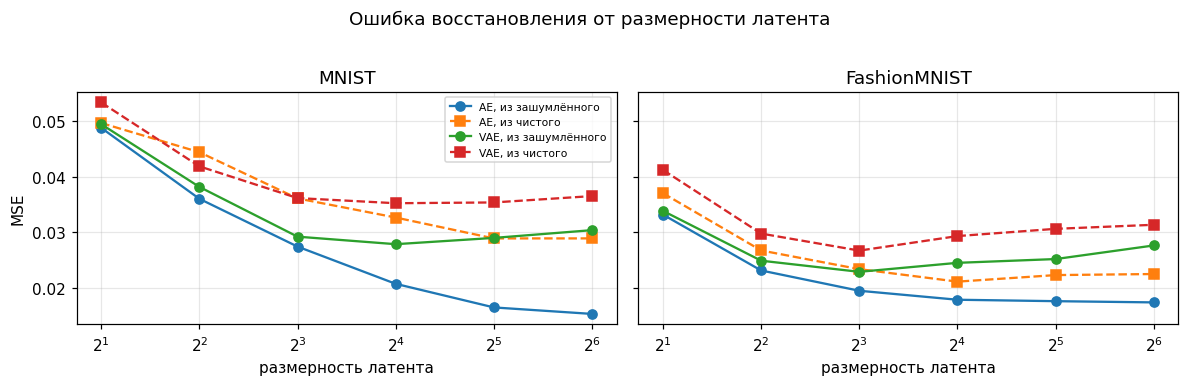

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    for m in MODELS:
        s = lat[(lat.dataset == ds) & (lat.model == m)].sort_values('latent')
        ax.plot(s.latent, s.mse_noisy, marker='o', label=f'{m}, из зашумлённого')
        ax.plot(s.latent, s.mse_clean, marker='s', ls='--', label=f'{m}, из чистого')
    ax.set_xscale('log', base=2); ax.set_xlabel('размерность латента')
    ax.set_title(ds); ax.grid(alpha=0.3)
axes[0].set_ylabel('MSE'); axes[0].legend(fontsize=7)
fig.suptitle('Ошибка восстановления от размерности латента', y=1.02)
plt.tight_layout()
plt.show()

## 6. Пункт 1в: количество и ширина слоёв кодера и декодера

In [12]:
HIDDENS = [(128,), (256,), (512, 256), (512, 256, 128)]
arch = pd.DataFrame([experiment('слои', ds, m, hidden=h)[0]
                     for ds in DATASETS for m in MODELS for h in HIDDENS])
arch['hidden'] = arch['hidden'].astype(str)
print('MSE восстановления по зашумлённому:')
show(arch, 'hidden', 'mse_noisy')
print('\nSSIM восстановления по зашумлённому:')
show(arch, 'hidden', 'ssim_noisy')
print('\nчисло параметров:')
show(arch, 'hidden', 'params')

MSE восстановления по зашумлённому:
dataset           MNIST         FashionMNIST        
model                AE     VAE           AE     VAE
hidden                                              
(128,)           0.0199  0.0323       0.0195  0.0268
(256,)           0.0165  0.0290       0.0177  0.0252
(512, 256)       0.0208  0.0406       0.0188  0.0259
(512, 256, 128)  0.0268  0.0485       0.0218  0.0328

SSIM восстановления по зашумлённому:
dataset           MNIST         FashionMNIST        
model                AE     VAE           AE     VAE
hidden                                              
(128,)           0.7469  0.5369       0.6181  0.4987
(256,)           0.7924  0.5905       0.6411  0.5288
(512, 256)       0.7629  0.5252       0.6331  0.5521
(512, 256, 128)  0.7007  0.4134       0.6019  0.4788

число параметров:
dataset            MNIST          FashionMNIST         
model                 AE      VAE           AE      VAE
hidden                                               

## 7. Пункты 1г и 1д: количество эпох и коэффициент обучения

In [13]:
rows = []
for ds in DATASETS:
    Xtr, Xval, _ = DATA[ds]
    Xtr_n = noise_normal(Xtr, BASE['level'], np.random.default_rng(20260905))
    Xval_n = noise_normal(Xval, BASE['level'], np.random.default_rng(1))
    for m in MODELS:
        for lr in [3e-4, 1e-3, 3e-3]:
            torch.manual_seed(20260905)
            model = MODELS[m](latent=BASE['latent'], hidden=BASE['hidden'])

            def measure(epoch):
                """Замер после 10, 20 и 40 эпох одного и того же обучения."""
                if epoch in (10, 20, 40):
                    mse, ssim = quality(Xval, reconstruct(model, Xval_n))
                    row = dict(stage='обучение', dataset=ds, model=m, **BASE)
                    row.update(epochs=epoch, lr=lr, mse_noisy=mse, ssim_noisy=ssim)
                    rows.append(row)

            train_ae(model, Xtr_n, Xtr, epochs=40, lr=lr, after_epoch=measure)
sched = pd.DataFrame(rows)
for ds in DATASETS:
    for m in MODELS:
        s = sched[(sched.dataset == ds) & (sched.model == m)]
        print(f'{ds}, {m}: MSE восстановления по зашумлённому')
        print(s.pivot_table(index='lr', columns='epochs', values='mse_noisy').round(4).to_string())
        print()

MNIST, AE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0325  0.0241  0.0178
0.0010  0.0214  0.0165  0.0140
0.0030  0.0163  0.0142  0.0140

MNIST, VAE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0457  0.0363  0.0293
0.0010  0.0356  0.0290  0.0247
0.0030  0.0328  0.0274  0.0255

FashionMNIST, AE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0260  0.0220  0.0187
0.0010  0.0203  0.0177  0.0154
0.0030  0.0171  0.0154  0.0149

FashionMNIST, VAE: MSE восстановления по зашумлённому
epochs      10      20      40
lr                            
0.0003  0.0346  0.0284  0.0256
0.0010  0.0317  0.0252  0.0224
0.0030  0.0289  0.0241  0.0230



## 8. Пункт 2: восстановление из чистых и зашумлённых изображений

In [14]:
def best_value(df, ds, m, column):
    """Значение column в строке с наименьшей MSE для выборки ds и модели m."""
    s = df[(df.dataset == ds) & (df.model == m)]
    return s.loc[s.mse_noisy.idxmin(), column]


HIDDEN_BY_NAME = {str(h): h for h in HIDDENS}  # строка из таблицы обратно в кортеж слоёв
best = {}
for ds in DATASETS:
    for m in MODELS:
        best[(ds, m)] = dict(latent=int(best_value(lat, ds, m, 'latent')),
                             hidden=HIDDEN_BY_NAME[best_value(arch, ds, m, 'hidden')],
                             epochs=int(best_value(sched, ds, m, 'epochs')),
                             lr=float(best_value(sched, ds, m, 'lr')))
print('параметры итоговых моделей:')
print(pd.DataFrame([dict(dataset=ds, model=m, **cfg) for (ds, m), cfg in best.items()])
      .to_string(index=False))

rows, models_final = [], {}
for ds in DATASETS:
    Xa, _, Xb = DATA[ds]
    Xa_n = noise_normal(Xa, BASE['level'], np.random.default_rng(20260905))
    Xb_n = noise_normal(Xb, BASE['level'], np.random.default_rng(1))
    for m in MODELS:
        cfg = best[(ds, m)]
        torch.manual_seed(20260905)
        model = MODELS[m](latent=cfg['latent'], hidden=cfg['hidden'])
        train_ae(model, Xa_n, Xa, epochs=cfg['epochs'], lr=cfg['lr'])
        models_final[(ds, m)] = model
        row = dict(stage='итог', dataset=ds, model=m, **BASE)
        row.update(cfg)
        row['mse_noisy'], row['ssim_noisy'] = quality(Xb, reconstruct(model, Xb_n))
        row['mse_clean'], row['ssim_clean'] = quality(Xb, reconstruct(model, Xb))
        row['params'] = sum(p.numel() for p in model.parameters())
        rows.append(row)
final = pd.DataFrame(rows)
print(f"\nкачество восстановления на тестовой выборке ({BASE['noise']} шум {BASE['level']}):")
print(final[['dataset', 'model', 'mse_clean', 'ssim_clean', 'mse_noisy', 'ssim_noisy']]
      .round(4).to_string(index=False))

allres = pd.concat([noi, lat, arch, sched, final], ignore_index=True)
allres['hidden'] = allres['hidden'].astype(str)
allres.to_csv('results.csv', index=False)

параметры итоговых моделей:
     dataset model  latent hidden  epochs    lr
       MNIST    AE      64 (256,)      40 0.001
       MNIST   VAE      16 (256,)      40 0.001
FashionMNIST    AE      64 (256,)      40 0.003
FashionMNIST   VAE       8 (256,)      40 0.001



качество восстановления на тестовой выборке (нормальный шум 0.3):
     dataset model  mse_clean  ssim_clean  mse_noisy  ssim_noisy
       MNIST    AE     0.0138      0.8288     0.0123      0.8420
       MNIST   VAE     0.0284      0.6850     0.0243      0.6755
FashionMNIST    AE     0.0209      0.7160     0.0141      0.6975
FashionMNIST   VAE     0.0238      0.6125     0.0208      0.5840


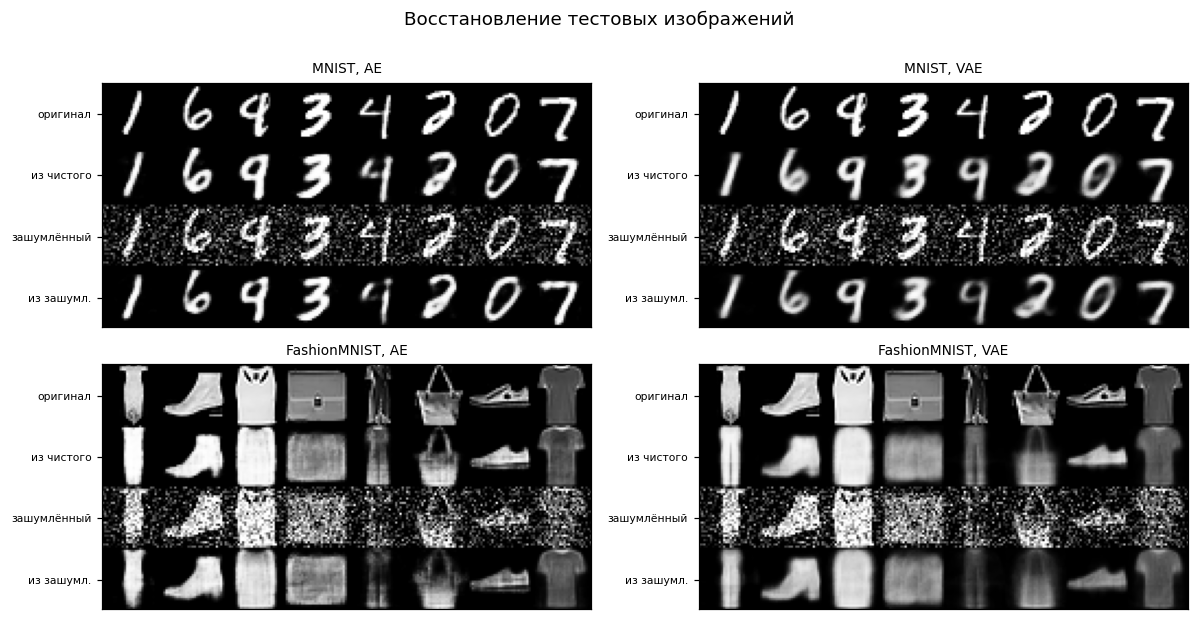

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6))
for i, ds in enumerate(DATASETS):
    Xb = DATA[ds][2]
    Xb_n = noise_normal(Xb, BASE['level'], np.random.default_rng(1))
    for j, m in enumerate(MODELS):
        model = models_final[(ds, m)]
        rec_c, rec_n = reconstruct(model, Xb[:8]), reconstruct(model, Xb_n[:8])
        # строки: оригинал, восстановленный по нему, зашумлённый, восстановленный по зашумлённому
        canvas = np.vstack([np.hstack(list(r)) for r in [Xb[:8], rec_c, Xb_n[:8], rec_n]])
        axes[i, j].imshow(canvas, cmap='gray')
        axes[i, j].set_title(f'{ds}, {m}', fontsize=9)
        axes[i, j].set_yticks([14, 42, 70, 98])
        axes[i, j].set_yticklabels(['оригинал', 'из чистого', 'зашумлённый', 'из зашумл.'], fontsize=7)
        axes[i, j].set_xticks([])
fig.suptitle('Восстановление тестовых изображений', y=1.0)
plt.tight_layout()
plt.show()

## 9. Пункт 3: генерирование новых изображений из случайных точек латентного пространства

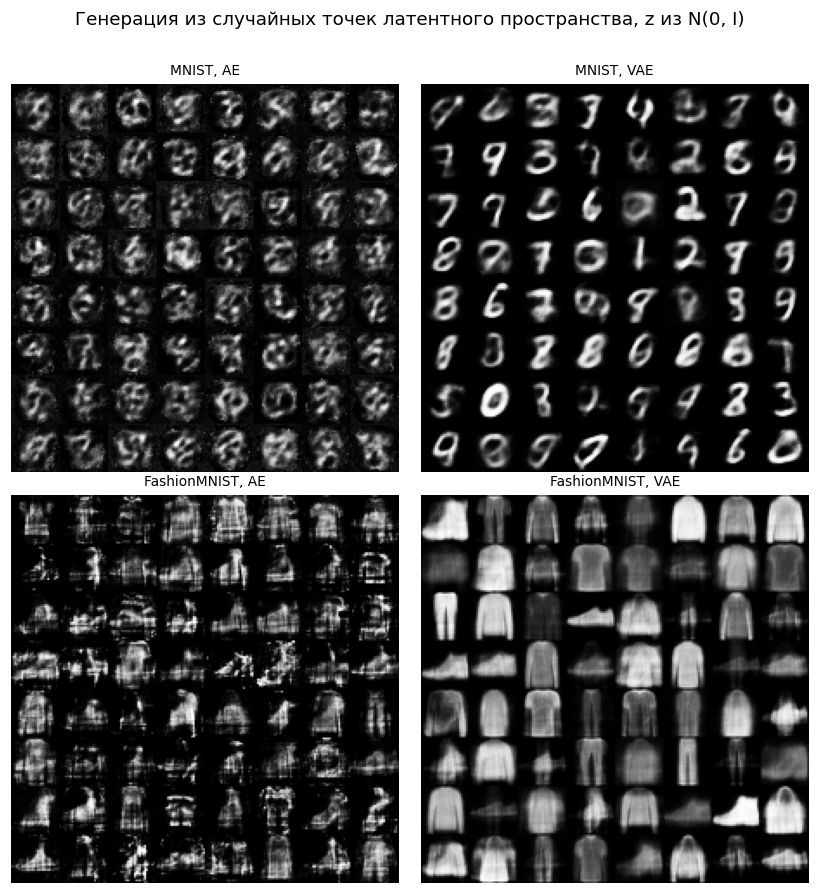

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(7.6, 8))
for i, ds in enumerate(DATASETS):
    for j, m in enumerate(MODELS):
        model = models_final[(ds, m)]
        model.eval()
        with torch.no_grad():
            imgs = model.sample(64).cpu().numpy().reshape(-1, 28, 28)
        # 64 изображения выкладываются в таблицу 8 на 8
        canvas = np.vstack([np.hstack([imgs[r * 8 + c] for c in range(8)])
                            for r in range(8)])
        axes[i, j].imshow(canvas, cmap='gray')
        axes[i, j].set_title(f'{ds}, {m}', fontsize=9)
        axes[i, j].axis('off')
fig.suptitle('Генерация из случайных точек латентного пространства, z из N(0, I)', y=1.01)
plt.tight_layout()
plt.show()